# A03-GN 




In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

REL = Path("project/experiments/thuan_deadline_2026_11_17")
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in [p, p / REL]]
BASE = next(q for q in candidates if (q / "run_experiments.py").is_file())
if str(BASE) not in sys.path: sys.path.insert(0, str(BASE))
import run_experiments as runner


In [2]:
EXPERIMENT = "A03-GN"
RUN_AGAIN = False
if RUN_AGAIN:
    with threadpool_limits(limits=1):
        rfm, cleaning, provenance = runner.prepare_input()
        runner.run_one(EXPERIMENT, rfm)
        runner.workbook(runner.assignments(), rfm, cleaning, provenance)
OUT = BASE / "results" / EXPERIMENT
params = json.loads((OUT / "parameters.json").read_text(encoding="utf-8"))
assert params["status"] == "completed"
display(pd.Series({
    "Thí nghiệm": EXPERIMENT,
    "Mô hình": params["actual_model"],
    "Khách": params["customers"],
    "Số chiều đầu vào": params["preprocessing"]["model_input_dimensions"],
    "Biến đổi": params["preprocessing"]["transform"],
    "Scaler": params["preprocessing"]["scaler"],
    "PCA": params["preprocessing"]["pca_requested"],
}).to_frame("Giá trị"))
print(json.dumps(params["preprocessing"], ensure_ascii=False, indent=2))


,Giá trị
Thí nghiệm,A03-GN
Mô hình,GNNClustering
Khách,4327
Số chiều đầu vào,2
Biến đổi,none
Scaler,StandardScaler
PCA,2


{
  "configuration": "A03",
  "transform": "none",
  "scaler": "StandardScaler",
  "pca_requested": 2,
  "model_input_dimensions": 2,
  "pca_explained_variance_ratio": [
    0.5638240337173058,
    0.30163072566982435
  ],
  "pca_explained_variance_total": 0.8654547593871302,
  "pca_components": [
    [
      -0.37402340703988635,
      0.6748844371544975,
      0.6361112225648374
    ],
    [
      0.9112201331059055,
      0.13978679633999763,
      0.3874758322675827
    ]
  ]
}


## Quét tham số và lựa chọn
GN dùng GNN Graph Autoencoder hai lớp GCN rồi K-Means trên embedding học được. Silhouette GN tính trên embedding; KM tính trên PCA/scaler input; DBSCAN tính trên khách không nhiễu. Các không gian này không so trực tiếp. Checkpoint GNN chọn theo BCE validation, không theo test.

,Được chọn
k,6
n_clusters,6
noise_pct,0.0
smallest_cluster,513
largest_cluster_pct_all,23.226254
silhouette,0.397036
dbi,0.86464
chi,1691.157201
inertia,3518.897044
eligible,True


,k,n_clusters,noise_pct,smallest_cluster,largest_cluster_pct_all,silhouette,dbi,chi,inertia,eligible
0,2,2,0.0,1308,69.771204,0.258627,1.627874,1074.723101,8334.076358,True
1,3,3,0.0,1269,37.300670,0.306003,1.472496,1214.408632,6662.610119,True
2,4,4,0.0,687,29.535475,0.349369,1.198808,1335.132830,5400.905668,True
3,5,5,0.0,524,26.785302,0.372277,1.033768,1477.496150,4395.092660,True
4,6,6,0.0,513,23.226254,0.397036,0.864640,1691.157201,3518.897044,True
5,7,7,0.0,25,23.180032,0.411328,0.758754,2062.951403,2691.966971,False
6,8,8,0.0,25,17.980125,0.420001,0.749956,2287.477179,2210.344914,False
7,9,9,0.0,25,16.847700,0.405578,0.780176,2298.670312,1978.603615,False
8,10,10,0.0,25,15.461058,0.397793,0.793036,2326.202288,1778.750390,False


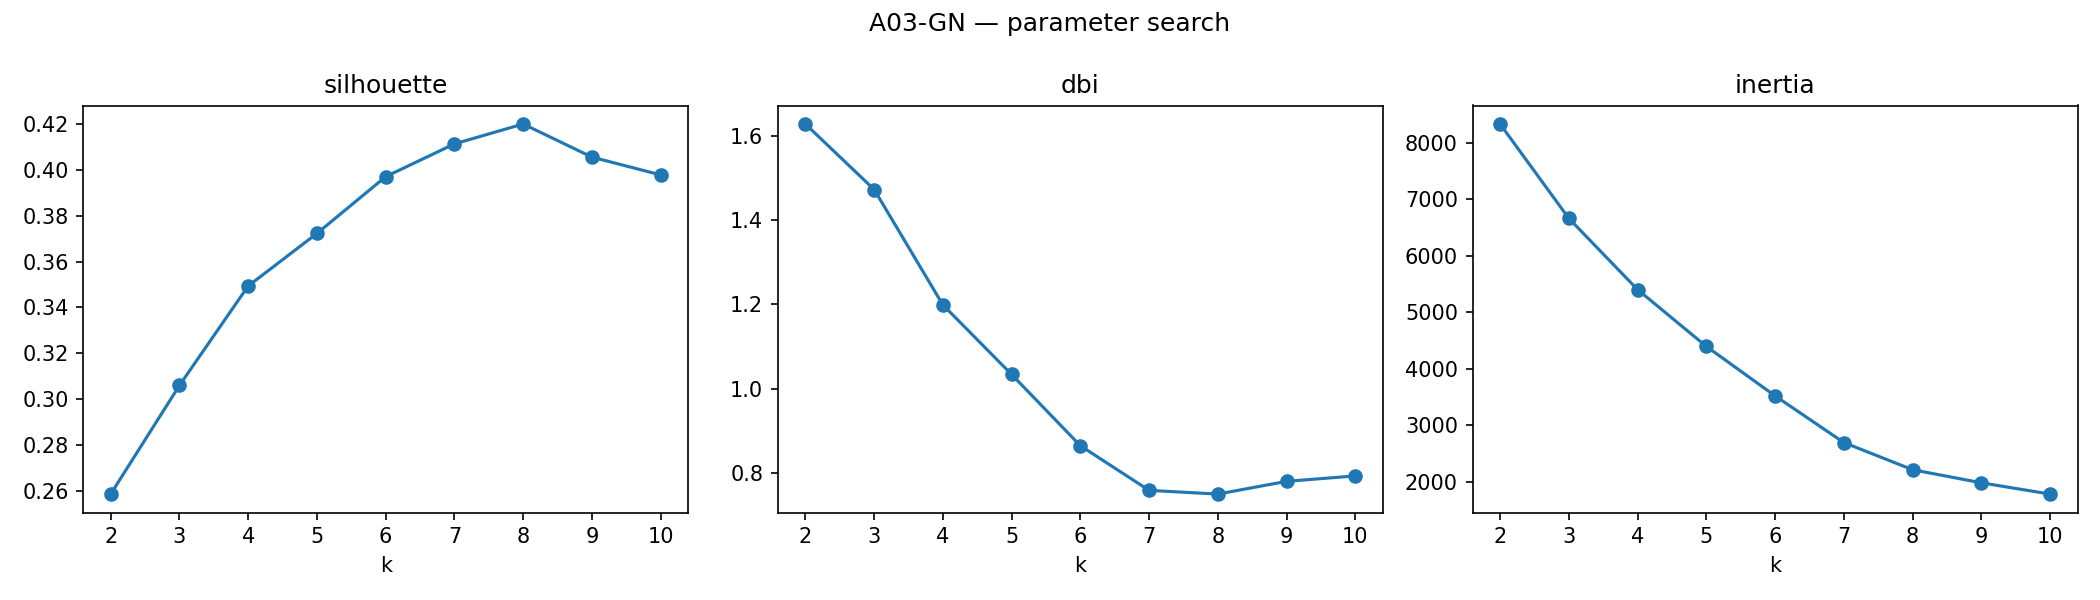

{
  "architecture": "GCN(input,32)-ReLU-GCN(32,8); inner-product edge decoder",
  "graph": "symmetrized union 15-nearest-neighbor Euclidean graph from PCA/model input",
  "message_passing": "D^-1/2 (A_train + I) D^-1/2; validation/test positives removed",
  "train_positive_edges": 30659,
  "validation_positive_edges": 3832,
  "test_positive_edges": 3832,
  "epochs_run": 200,
  "best_epoch": 199,
  "initial_validation_bce": 0.6602451205253601,
  "best_validation_bce": 0.47894251346588135,
  "initial_validation_diagnostic": {
    "roc_auc": 0.7188716952288388,
    "average_precision": 0.6853592729081581
  },
  "validation_link_metrics": {
    "roc_auc": 0.941244188320745,
    "average_precision": 0.9175114994061194
  },
  "test_link_metrics": {
    "roc_auc": 0.9459416445840108,
    "average_precision": 0.9253973752936511
  },
  "test_usage": "evaluated once after validation checkpoint selection; never used for training or cluster-k selection",
  "negative_sampling": "1:1 uniform non-edg

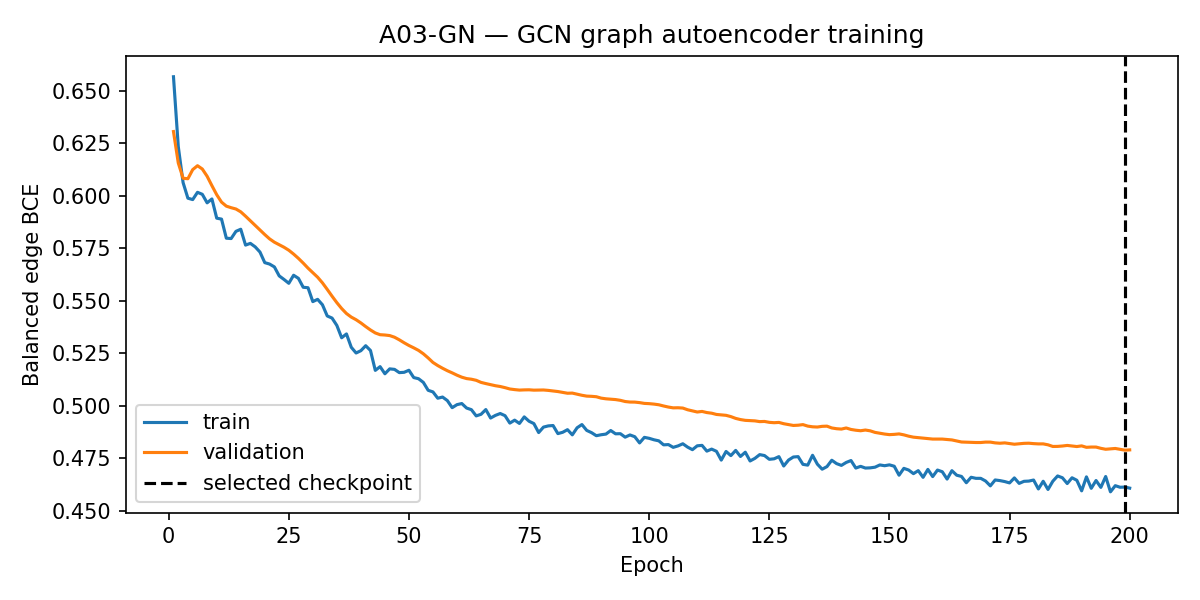

,epoch,train_link_bce,validation_link_bce
0,1,0.656541,0.630479
1,2,0.623317,0.615533
2,3,0.606202,0.608259
3,4,0.598783,0.608043
4,5,0.598119,0.612364
...,...,...,...
195,196,0.459120,0.479528
196,197,0.462047,0.479741
197,198,0.461295,0.479341
198,199,0.461383,0.478943


In [3]:
grid = pd.read_csv(OUT / "search.csv")
display(pd.Series(params["selected"]).to_frame("Được chọn"))
display(grid)
display(Image(filename=str(OUT / "figures" / "search.png")))
if "gnn_training" in params:
    print(json.dumps(params["gnn_training"], ensure_ascii=False, indent=2))
    display(Image(filename=str(OUT / "figures" / "training.png")))
    display(pd.read_csv(OUT / "training_history.csv"))


## Nhãn và hồ sơ cụm
Hình chỉ hiển thị hai tọa độ đầu; bảng RFM dùng đơn vị gốc.

,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,5
1,12348,76,4,1437.24,2
2,12349,19,1,1457.55,3
3,12350,311,1,294.40,4
4,12352,37,7,1385.74,2
5,12353,205,1,89.00,1
6,12354,233,1,1079.40,1
7,12355,215,1,459.40,1
8,12356,23,3,2487.43,2
9,12357,34,1,6207.67,2


,cluster,customers,Recency_median,Frequency_median,Monetary_median,Monetary_sum,customer_pct,monetary_pct
0,0,740,60.0,1.0,347.18,319194.301,17.101918,3.792803
1,1,796,172.0,2.0,383.60,2318603.411,18.396117,27.550638
2,2,717,54.0,4.0,1582.60,1450144.151,16.570372,17.231234
3,3,1005,15.0,3.0,693.23,860573.380,23.226254,10.225701
4,4,513,303.0,1.0,265.85,193601.490,11.855789,2.300456
5,5,556,9.0,11.0,4037.89,3273671.640,12.849549,38.899168


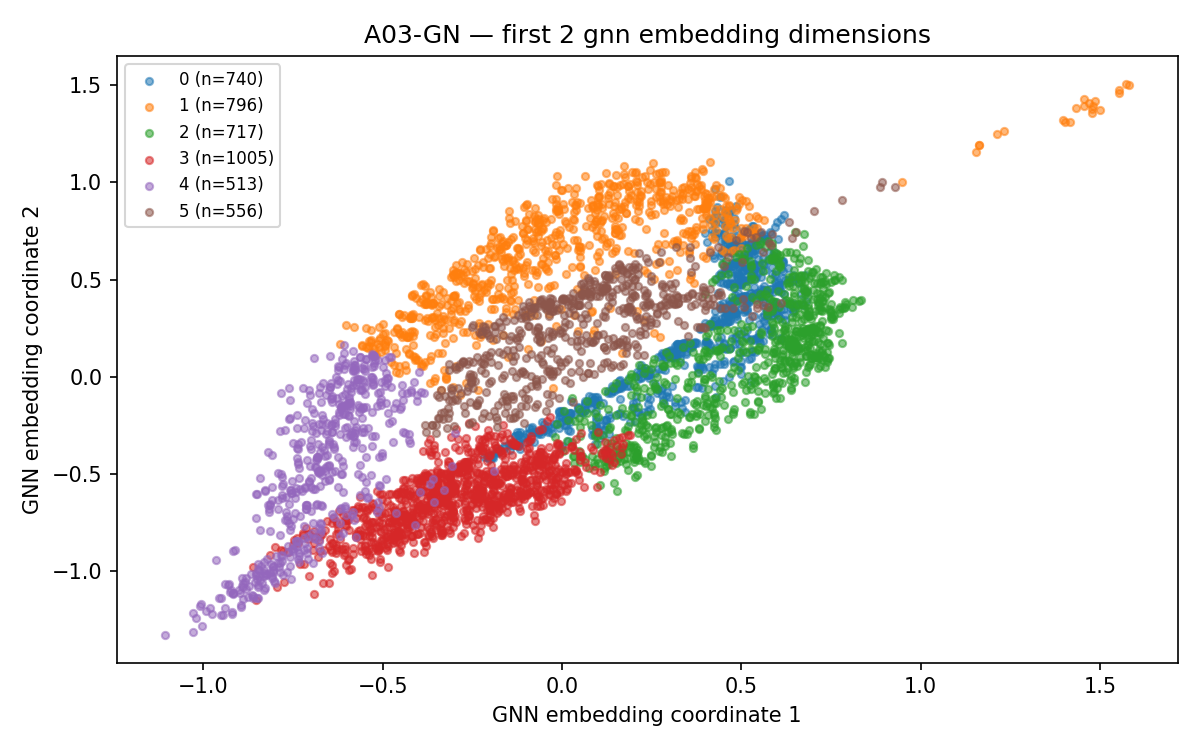

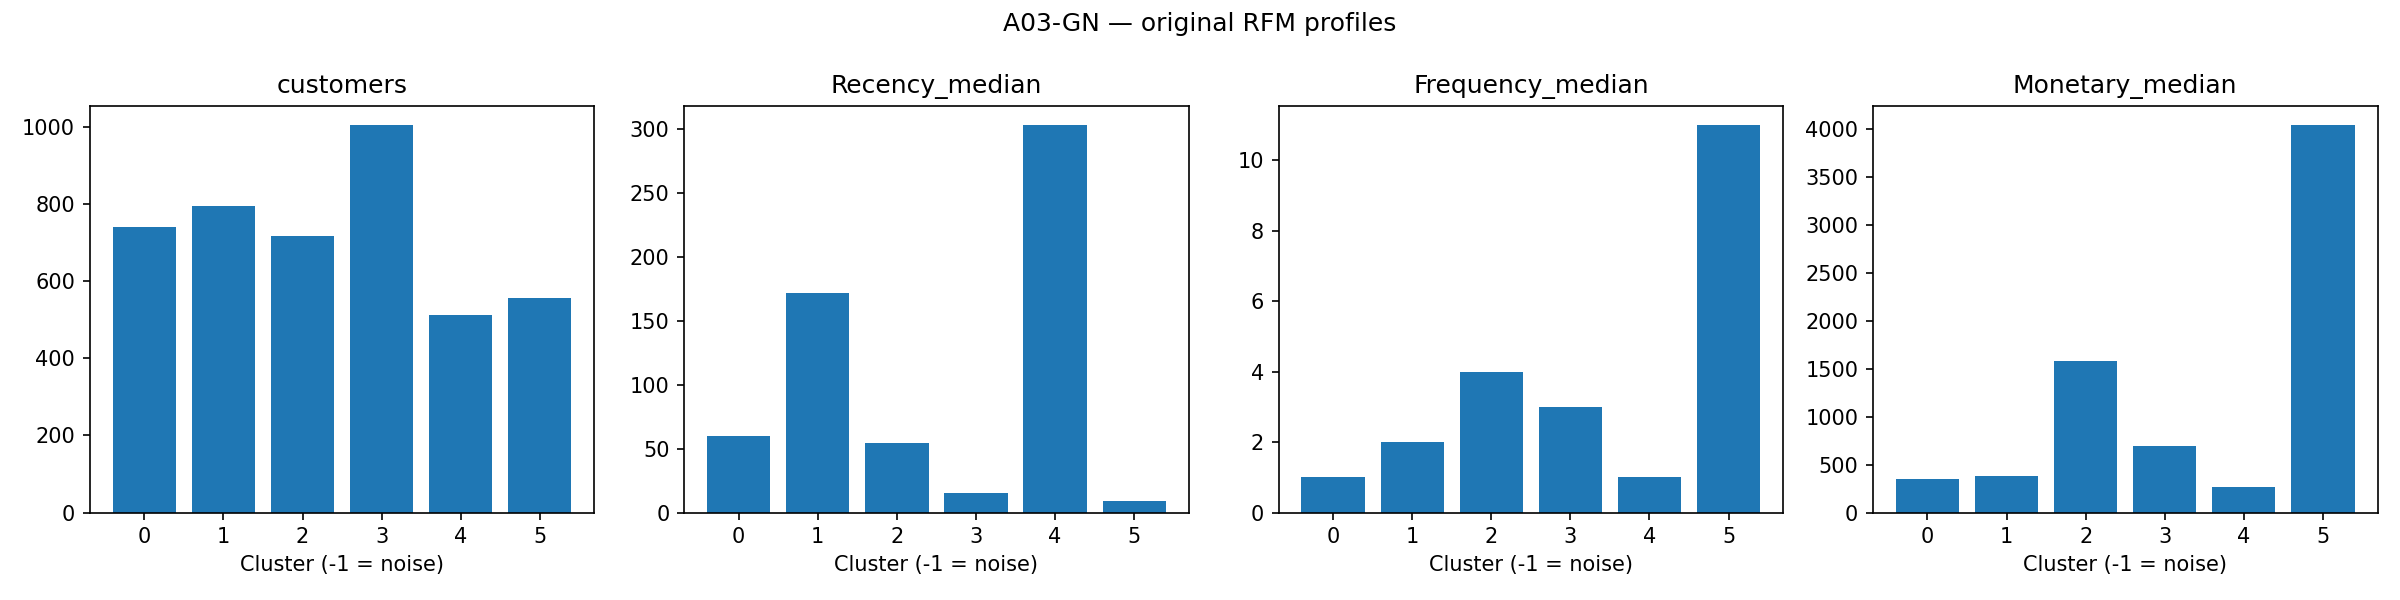

In [4]:
labels = pd.read_csv(OUT / "labels.csv", dtype={"CustomerID": str})
profiles = pd.read_csv(OUT / "profiles.csv")
assert labels.CustomerID.is_unique and len(labels) == params["customers"]
display(labels.head(10))
display(profiles)
display(Image(filename=str(OUT / "figures" / "clusters.png")))
display(Image(filename=str(OUT / "figures" / "profiles.png")))
if (OUT / "figures" / "k_distance.png").exists():
    display(Image(filename=str(OUT / "figures" / "k_distance.png")))


## Đối chiếu và giới hạn
Parent diagnostic giữ tham số đã chọn ở target, không phải baseline được tune độc lập. GNN dùng đồ thị kNN từ RFM, nên AUC/AP liên kết chỉ đánh giá tái dựng graph; không có BIC/AIC. GNN có tính transductive: suy luận chỉ áp dụng tập khách gốc đúng thứ tự.

In [5]:
if params.get("comparison"):
    print(json.dumps(params["comparison"], ensure_ascii=False, indent=2))
print("Chỉ số trên StandardScaler(RFM gốc), dùng cùng không gian tham chiếu:")
display(pd.Series(params["all_customers_common_space_scores"]).to_frame("Giá trị"))
display(Markdown("\n".join("- " + note for note in params["limitations"])))


{
  "parent_configuration": "A01",
  "purpose": "fixed-parameter preprocessing diagnostic, not a tuned parent experiment",
  "target_dimensions": 2,
  "parent_dimensions": 3,
  "ari": 0.8013379660066936,
  "target_common_rfm_scores": {
    "n_clusters": 6,
    "noise_pct": 0.0,
    "smallest_cluster": 513,
    "largest_cluster_pct_all": 23.22625375548879,
    "silhouette": 0.25489644681311074,
    "dbi": 1.1081672035249943,
    "chi": 558.9720144170914
  },
  "parent_common_rfm_scores": {
    "n_clusters": 6,
    "noise_pct": 0.0,
    "smallest_cluster": 475,
    "largest_cluster_pct_all": 22.14005084354056,
    "silhouette": 0.26663531973910437,
    "dbi": 1.0167652091896437,
    "chi": 703.563940425087
  },
  "parent_input_scores": {
    "n_clusters": 6,
    "noise_pct": 0.0,
    "smallest_cluster": 475,
    "largest_cluster_pct_all": 22.14005084354056,
    "silhouette": 0.26663531973910454,
    "dbi": 1.0167652091896404,
    "chi": 703.5639404250892
  },
  "parent_preprocessing": {


,Giá trị
n_clusters,6.000000
noise_pct,0.000000
smallest_cluster,513.000000
largest_cluster_pct_all,23.226254
silhouette,0.254896
dbi,1.108167
chi,558.972014


- Exploratory clustering, not future value prediction; Monetary is historical sales, not profit.
- No ground-truth labels or held-out predictive evaluation.
- Internal scores from different feature spaces and DBSCAN subsets are not directly comparable.
- The cleaning policy reproduces the shared group RFM; it is not a newly approved official policy.
- Transductive GNN: graph/embeddings apply to the fitted customers and their original order; unseen nodes require graph reconstruction and retraining.
- Held-out link prediction evaluates reconstruction of an RFM-derived graph, not business outcomes, customer value prediction, or segmentation ground truth.
- Only one fixed random seed and one GNN architecture are evaluated; graph and architecture choices are explicit implementation assumptions.